# Major Project 3 — Complete Cleaning, EDA & Accuracy Improvement
### College Admission Prediction

This notebook performs the complete basic data-science workflow: data loading, inspection, cleaning, missing-value handling, duplicate checks, outlier detection, descriptive statistics, 20+ visualizations, correlation matrix, boxplots, feature engineering, baseline classification, improved classification, metrics, confusion matrix and ROC curve.

In [1]:
# 1. Libraries
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [9]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

file_path = next(iter(uploaded))
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Saving College_Admission.csv to College_Admission.csv
Dataset loaded successfully!
Shape: (25000, 13)


,student_id,age,gender,category,state,preferred_stream,entrance_exam,entrance_score,board_percentage,extracurricular_score,admission_probability,admission_status,scholarship_eligibility
0,250.99,17,other,general,odisha,management,cet,30,95.58,2,0.387,admitted,yes
1,250.99,20,other,ews,gujarat,agriculture,none,0,75.45,2,0.221,rejected,no
2,250.99,19,female,sc,uttar pradesh,pharmacy,cet,120,75.36,10,0.446,rejected,no
3,250.99,18,male,ews,meghalaya,arts,cet,179,52.49,2,0.174,admitted,no
4,250.99,18,male,sc,rajasthan,engineering,jee,295,92.48,7,0.634,admitted,yes


In [10]:
# 3. Basic inspection
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

print("\nMissing values:")
display(df.isnull().sum().to_frame("missing"))

print("\nDuplicate rows:", df.duplicated().sum())

if "student_id" in df.columns:
    print("Duplicate student IDs:", df["student_id"].duplicated().sum())

print("\nUnique values:")
display(df.nunique().sort_values().to_frame("unique_count"))

Column names:
['student_id', 'age', 'gender', 'category', 'state', 'preferred_stream', 'entrance_exam', 'entrance_score', 'board_percentage', 'extracurricular_score', 'admission_probability', 'admission_status', 'scholarship_eligibility']

Data types:


,dtype
student_id,float64
age,int64
gender,object
category,object
state,object
preferred_stream,object
entrance_exam,object
entrance_score,int64
board_percentage,float64
extracurricular_score,int64



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,25000.0,NaN,NaN,NaN,12500.5,7212.732314,250.99,6250.75,12500.5,18750.25,24750.01
age,25000.0,NaN,NaN,NaN,18.49244,1.116205,17.0,17.0,18.0,19.0,20.0
gender,25000,3,other,8387,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,25000,5,st,5081,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,25000,26,rajasthan,1031,NaN,NaN,NaN,NaN,NaN,NaN,NaN
preferred_stream,25000,12,management,2163,NaN,NaN,NaN,NaN,NaN,NaN,NaN
entrance_exam,25000,4,none,11288,NaN,NaN,NaN,NaN,NaN,NaN,NaN
entrance_score,25000.0,NaN,NaN,NaN,77.87976,120.356125,0.0,0.0,20.0,126.0,634.0
board_percentage,25000.0,NaN,NaN,NaN,75.028014,14.438767,50.44,62.55,75.07,87.64,99.53
extracurricular_score,25000.0,NaN,NaN,NaN,4.99092,3.158942,0.0,2.0,5.0,8.0,10.0



Missing values:


,missing
student_id,0
age,0
gender,0
category,0
state,0
preferred_stream,0
entrance_exam,0
entrance_score,0
board_percentage,0
extracurricular_score,0



Duplicate rows: 0
Duplicate student IDs: 498

Unique values:


,unique_count
scholarship_eligibility,2
admission_status,2
gender,3
age,4
entrance_exam,4
category,5
extracurricular_score,11
preferred_stream,12
state,26
entrance_score,616


In [12]:
# 4. Cleaning
clean_df = df.dropna(how="all").drop_duplicates().copy()
clean_df.columns = [c.strip() for c in clean_df.columns]

# Standardize text categories
for col in clean_df.select_dtypes(include="object").columns:
    clean_df[col] = clean_df[col].astype(str).str.strip().str.lower()

# Remove identifier from predictive data
if "student_id" in clean_df.columns:
    clean_df = clean_df.drop(columns=["student_id"])

# Missing-value treatment
for col in clean_df.select_dtypes(include=np.number).columns:
    clean_df[col] = clean_df[col].fillna(clean_df[col].median())

for col in clean_df.select_dtypes(include="object").columns:
    clean_df[col] = clean_df[col].fillna(clean_df[col].mode()[0])

print("Cleaned shape:", clean_df.shape)
print("Missing values after cleaning:", clean_df.isnull().sum().sum())
print("Duplicate rows after cleaning:", clean_df.duplicated().sum())

clean_df.to_csv("College_Admission_cleaned.csv", index=False)
print("Saved: College_Admission_cleaned.csv")

Cleaned shape: (25000, 12)
Missing values after cleaning: 0
Duplicate rows after cleaning: 0
Saved: College_Admission_cleaned.csv


In [13]:
# 5. Outlier report using IQR
num_cols = clean_df.select_dtypes(include=np.number).columns.tolist()
outlier_rows = []

for col in num_cols:
    q1 = clean_df[col].quantile(.25)
    q3 = clean_df[col].quantile(.75)
    iqr = q3 - q1
    low, high = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((clean_df[col] < low) | (clean_df[col] > high)).sum()
    outlier_rows.append([col, q1, q3, low, high, int(n)])

outlier_report = pd.DataFrame(
    outlier_rows,
    columns=["Feature","Q1","Q3","Lower Bound","Upper Bound","Outlier Count"]
)
display(outlier_report.sort_values("Outlier Count", ascending=False))

print("Outliers are visualized and reported rather than automatically deleted,")
print("because extreme applicant values may be legitimate observations.")

,Feature,Q1,Q3,Lower Bound,Upper Bound,Outlier Count
1,entrance_score,0.000,126.000,-189.000,315.000,1156
4,admission_probability,0.219,0.419,-0.081,0.719,286
0,age,17.000,19.000,14.000,22.000,0
2,board_percentage,62.550,87.640,24.915,125.275,0
3,extracurricular_score,2.000,8.000,-7.000,17.000,0


Outliers are visualized and reported rather than automatically deleted,
because extreme applicant values may be legitimate observations.


## Exploratory Data Analysis — Visualizations

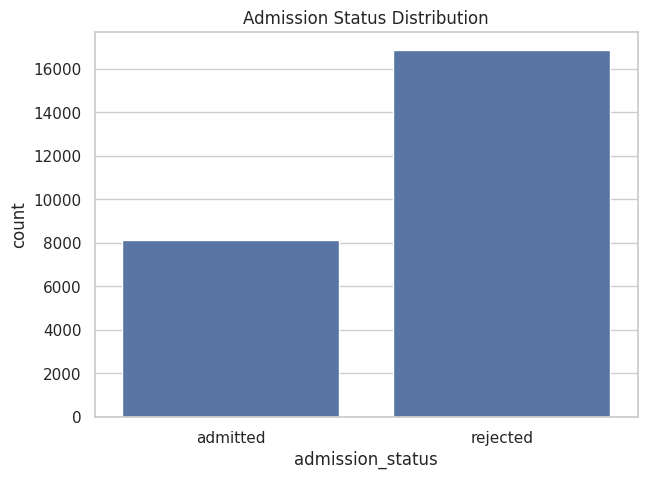

In [14]:
# Plot 1: Target distribution
plt.figure(figsize=(7,5)); sns.countplot(data=clean_df, x="admission_status")
plt.title("Admission Status Distribution"); plt.show()

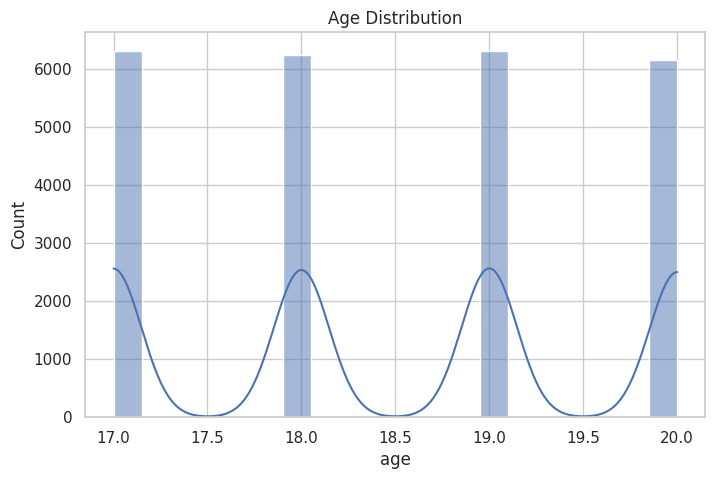

In [15]:
# Plot 2: Age distribution
plt.figure(figsize=(8,5)); sns.histplot(clean_df["age"], bins=20, kde=True)
plt.title("Age Distribution"); plt.show()

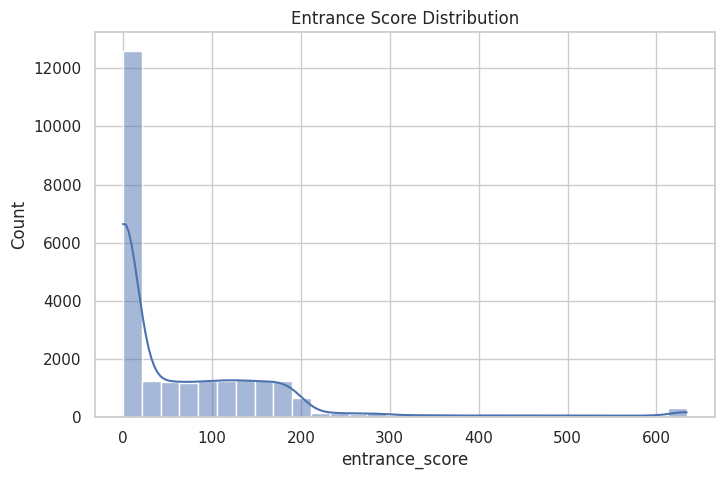

In [16]:
# Plot 3: Entrance score distribution
plt.figure(figsize=(8,5)); sns.histplot(clean_df["entrance_score"], bins=30, kde=True)
plt.title("Entrance Score Distribution"); plt.show()

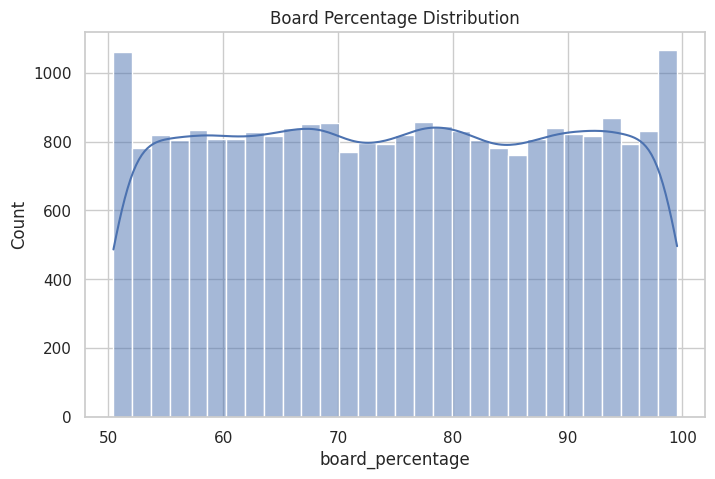

In [17]:
# Plot 4: Board percentage distribution
plt.figure(figsize=(8,5)); sns.histplot(clean_df["board_percentage"], bins=30, kde=True)
plt.title("Board Percentage Distribution"); plt.show()

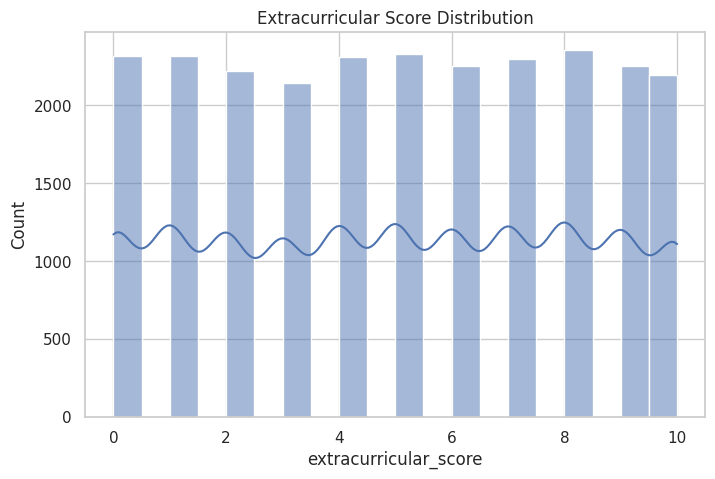

In [18]:
# Plot 5: Extracurricular score distribution
plt.figure(figsize=(8,5)); sns.histplot(clean_df["extracurricular_score"], bins=20, kde=True)
plt.title("Extracurricular Score Distribution"); plt.show()

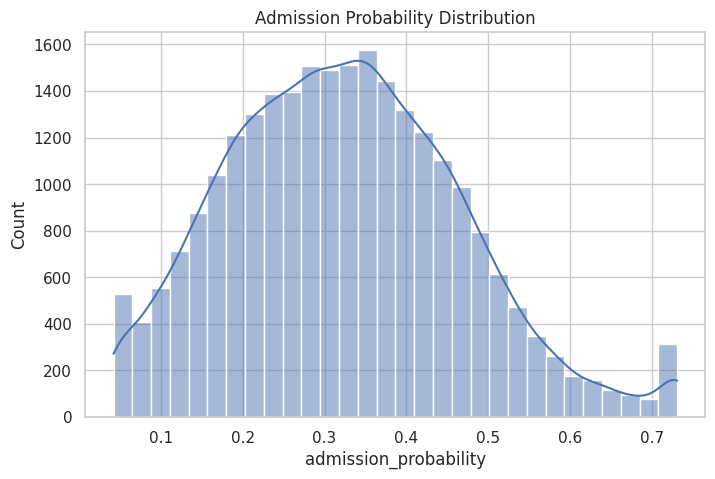

In [19]:
# Plot 6: Admission probability distribution
plt.figure(figsize=(8,5)); sns.histplot(clean_df["admission_probability"], bins=30, kde=True)
plt.title("Admission Probability Distribution"); plt.show()

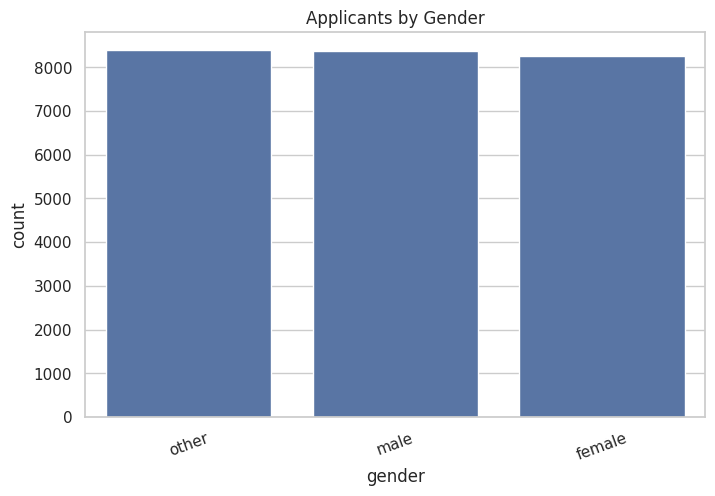

In [20]:
# Plot 7: Gender count
plt.figure(figsize=(8,5)); sns.countplot(data=clean_df, x="gender", order=clean_df["gender"].value_counts().index)
plt.title("Applicants by Gender"); plt.xticks(rotation=20); plt.show()

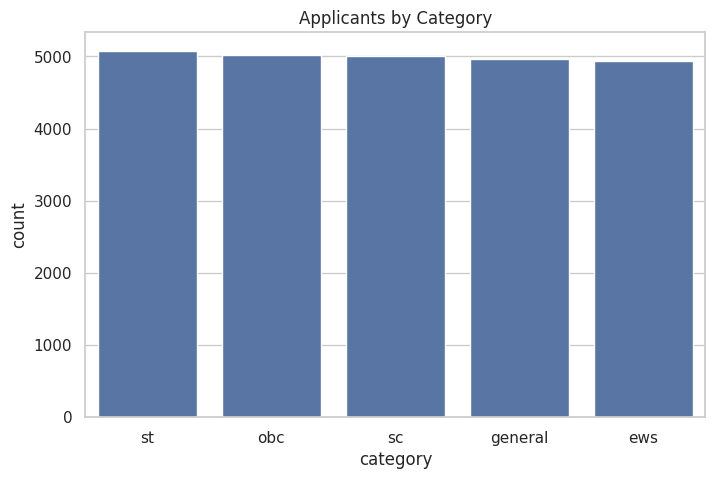

In [21]:
# Plot 8: Category count
plt.figure(figsize=(8,5)); sns.countplot(data=clean_df, x="category", order=clean_df["category"].value_counts().index)
plt.title("Applicants by Category"); plt.show()

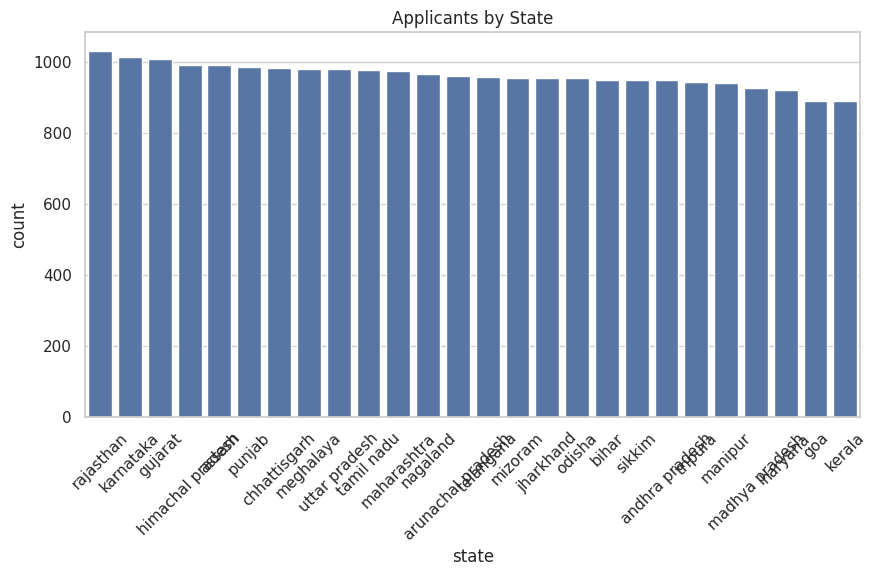

In [22]:
# Plot 9: State count
plt.figure(figsize=(10,5)); sns.countplot(data=clean_df, x="state", order=clean_df["state"].value_counts().index)
plt.title("Applicants by State"); plt.xticks(rotation=45); plt.show()

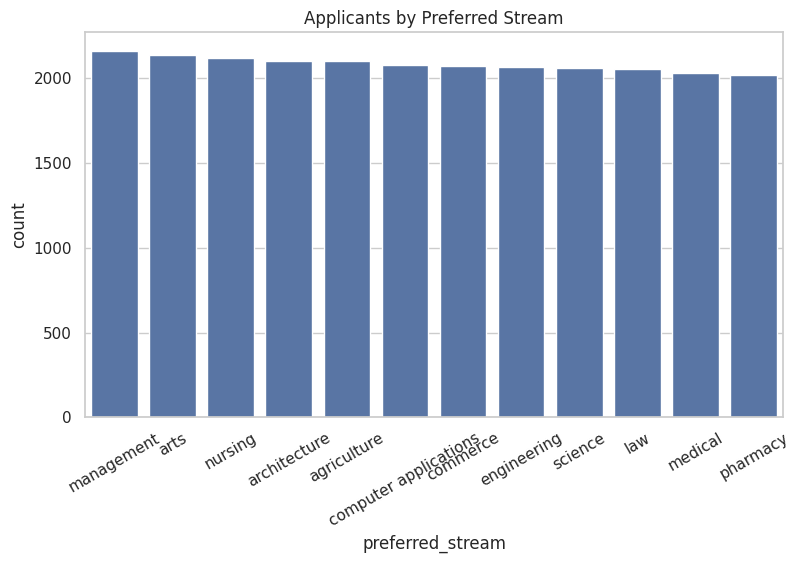

In [23]:
# Plot 10: Preferred stream count
plt.figure(figsize=(9,5)); sns.countplot(data=clean_df, x="preferred_stream", order=clean_df["preferred_stream"].value_counts().index)
plt.title("Applicants by Preferred Stream"); plt.xticks(rotation=30); plt.show()

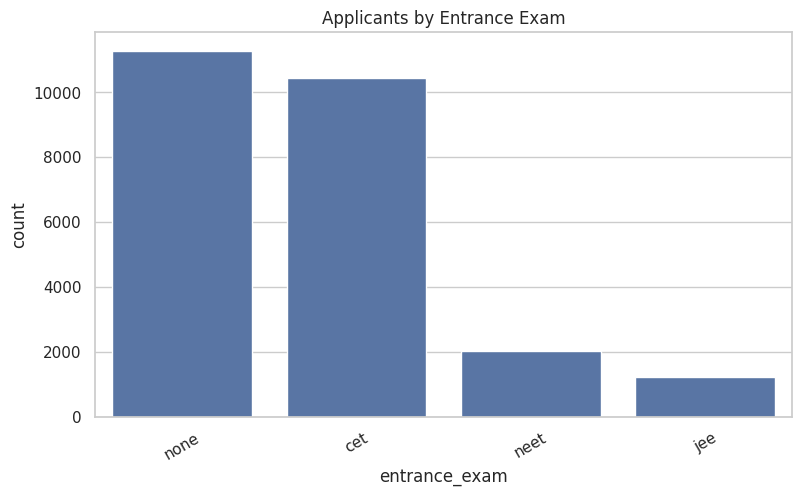

In [24]:
# Plot 11: Entrance exam count
plt.figure(figsize=(9,5)); sns.countplot(data=clean_df, x="entrance_exam", order=clean_df["entrance_exam"].value_counts().index)
plt.title("Applicants by Entrance Exam"); plt.xticks(rotation=30); plt.show()

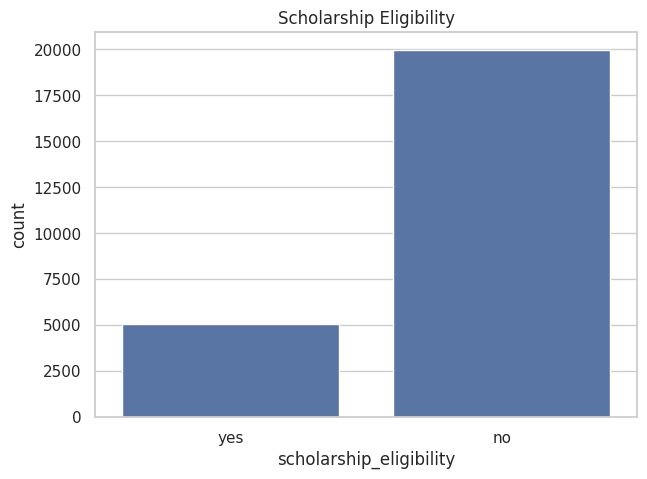

In [25]:
# Plot 12: Scholarship eligibility
plt.figure(figsize=(7,5)); sns.countplot(data=clean_df, x="scholarship_eligibility")
plt.title("Scholarship Eligibility"); plt.show()

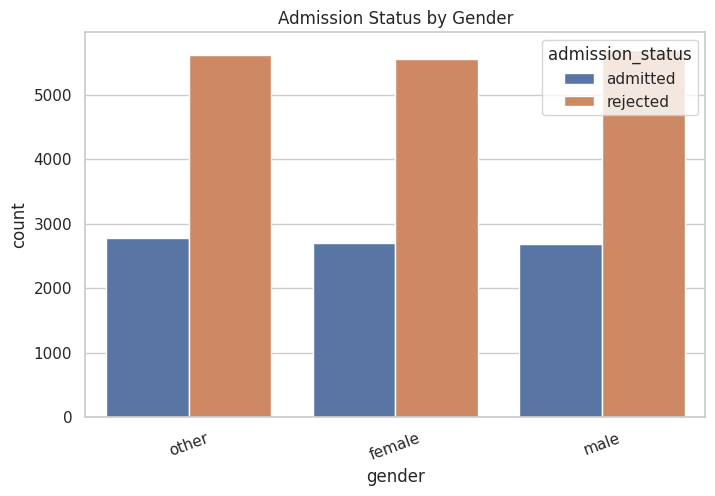

In [26]:
# Plot 13: Status by gender
plt.figure(figsize=(8,5)); sns.countplot(data=clean_df, x="gender", hue="admission_status")
plt.title("Admission Status by Gender"); plt.xticks(rotation=20); plt.show()

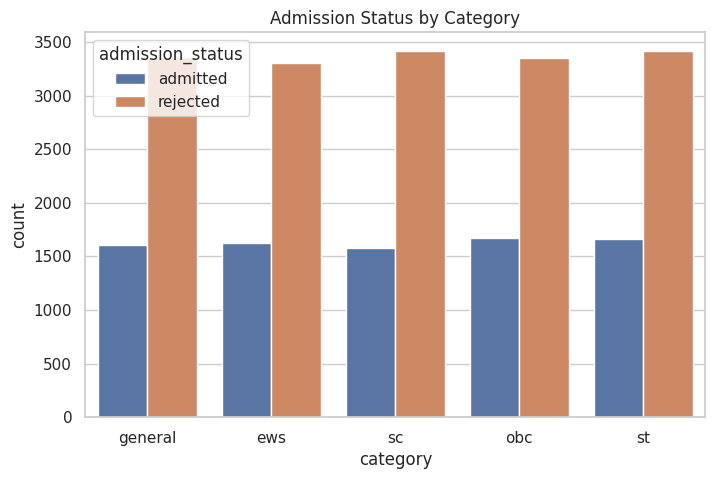

In [27]:
# Plot 14: Status by category
plt.figure(figsize=(8,5)); sns.countplot(data=clean_df, x="category", hue="admission_status")
plt.title("Admission Status by Category"); plt.show()

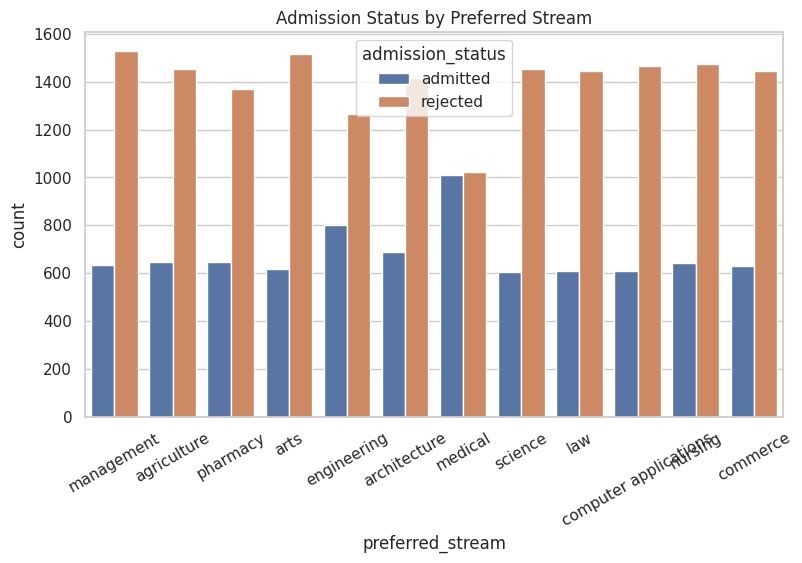

In [28]:
# Plot 15: Status by preferred stream
plt.figure(figsize=(9,5)); sns.countplot(data=clean_df, x="preferred_stream", hue="admission_status")
plt.title("Admission Status by Preferred Stream"); plt.xticks(rotation=30); plt.show()

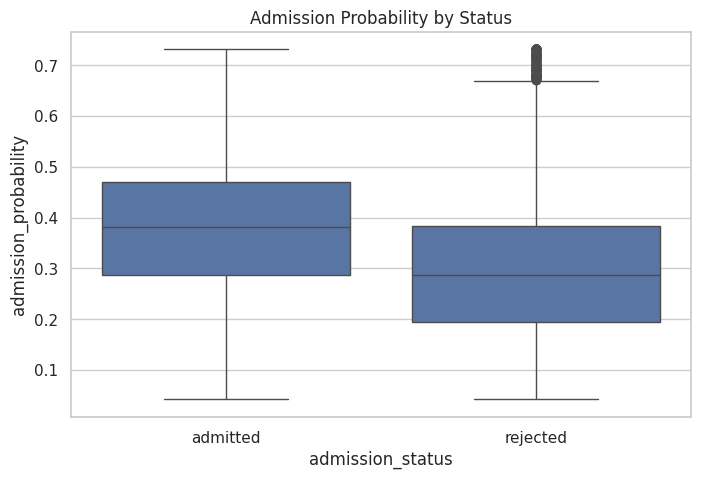

In [29]:
# Plot 16: Probability by status
plt.figure(figsize=(8,5)); sns.boxplot(data=clean_df, x="admission_status", y="admission_probability")
plt.title("Admission Probability by Status"); plt.show()

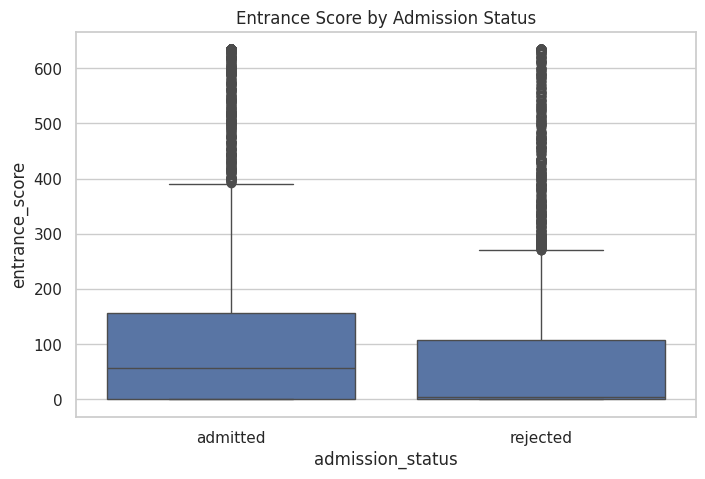

In [30]:
# Plot 17: Entrance score by status
plt.figure(figsize=(8,5)); sns.boxplot(data=clean_df, x="admission_status", y="entrance_score")
plt.title("Entrance Score by Admission Status"); plt.show()

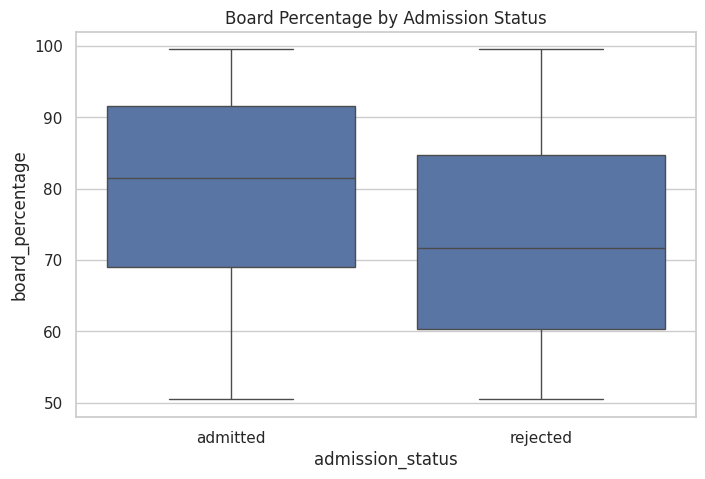

In [31]:
# Plot 18: Board percentage by status
plt.figure(figsize=(8,5)); sns.boxplot(data=clean_df, x="admission_status", y="board_percentage")
plt.title("Board Percentage by Admission Status"); plt.show()

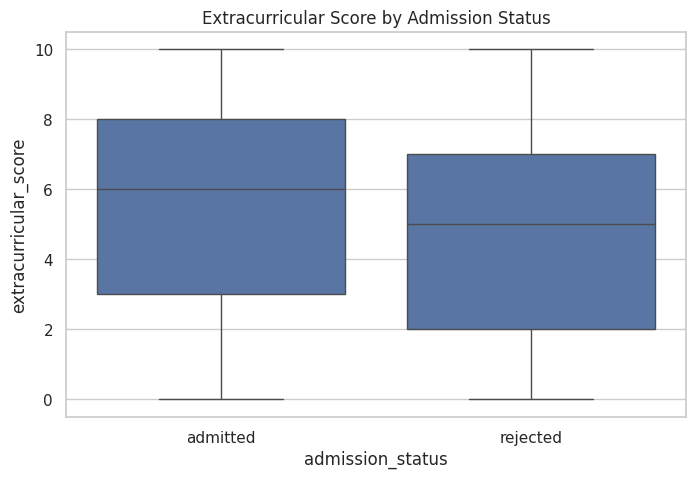

In [32]:
# Plot 19: Extracurricular score by status
plt.figure(figsize=(8,5)); sns.boxplot(data=clean_df, x="admission_status", y="extracurricular_score")
plt.title("Extracurricular Score by Admission Status"); plt.show()

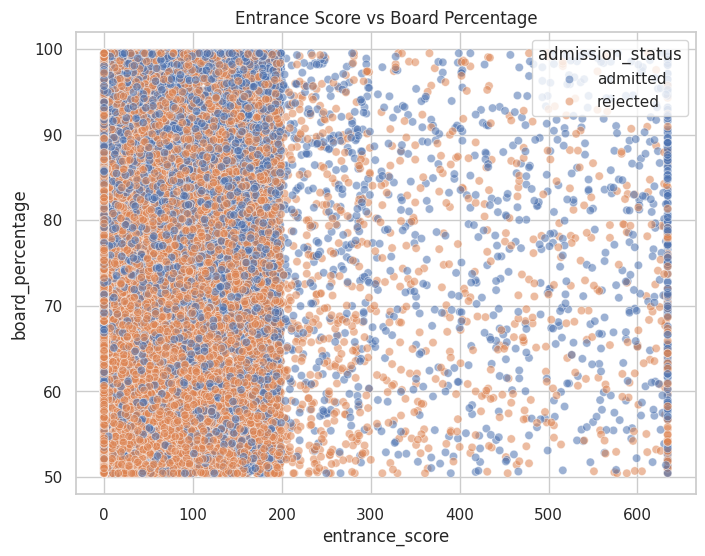

In [33]:
# Plot 20: Entrance score vs board percentage
plt.figure(figsize=(8,6)); sns.scatterplot(data=clean_df, x="entrance_score", y="board_percentage", hue="admission_status", alpha=.55)
plt.title("Entrance Score vs Board Percentage"); plt.show()

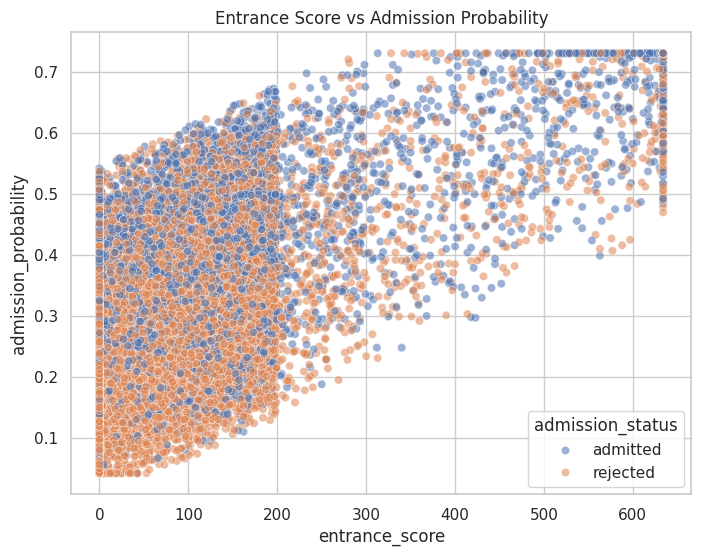

In [34]:
# Plot 21: Entrance score vs admission probability
plt.figure(figsize=(8,6)); sns.scatterplot(data=clean_df, x="entrance_score", y="admission_probability", hue="admission_status", alpha=.55)
plt.title("Entrance Score vs Admission Probability"); plt.show()

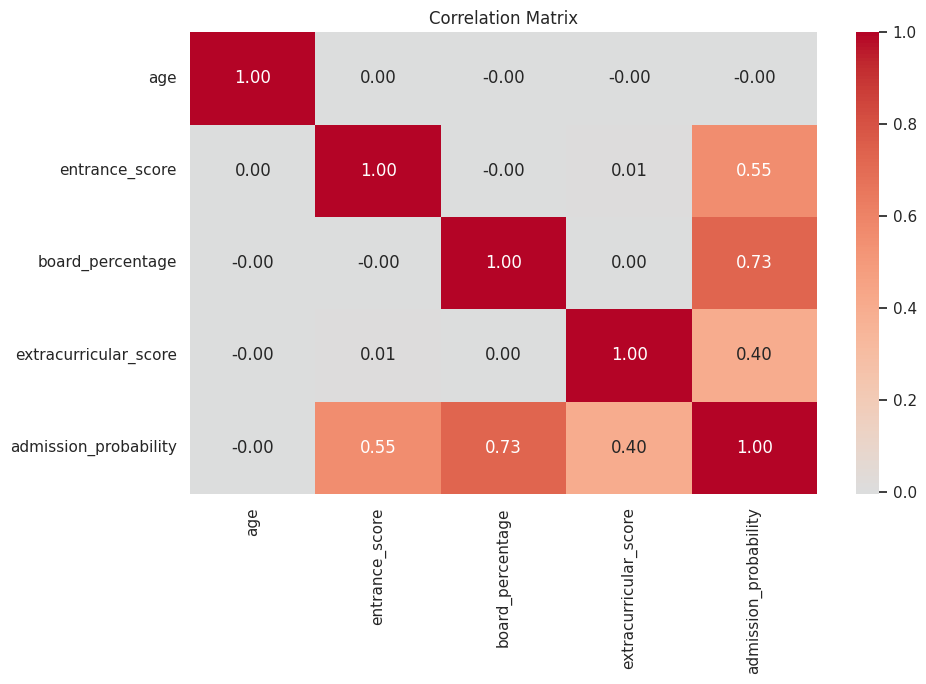

In [35]:
# Plot 22: Correlation matrix
corr = clean_df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10,7)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix"); plt.tight_layout(); plt.show()

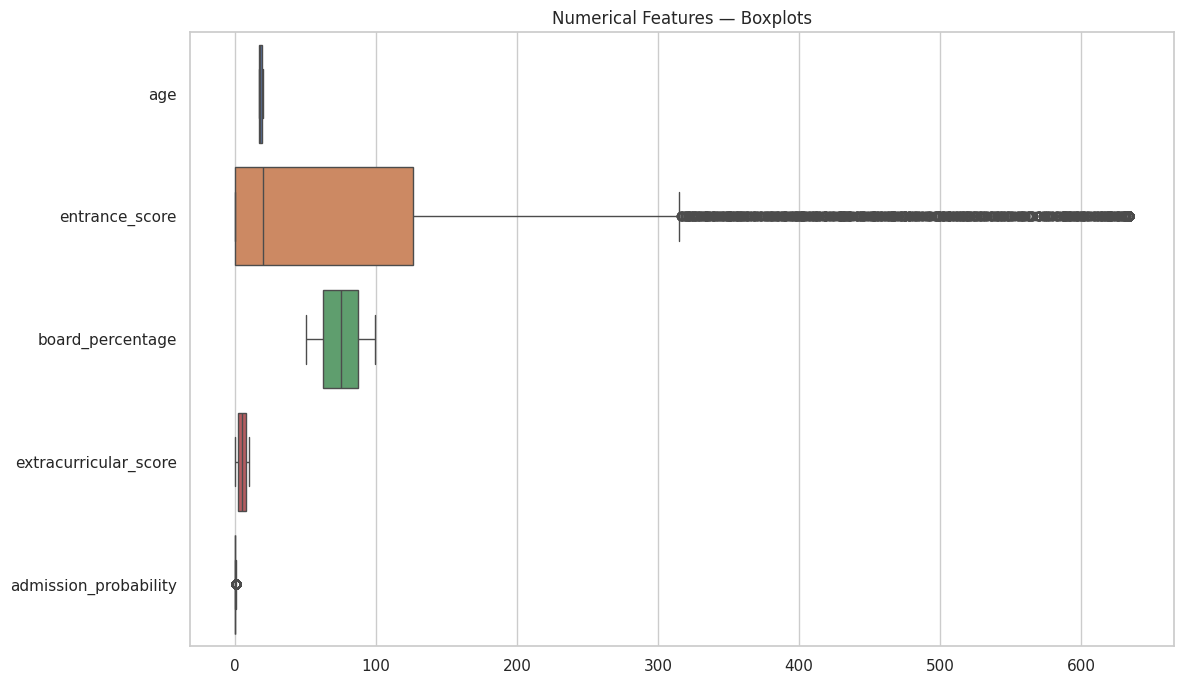

In [36]:
# Plot 23: Numerical boxplot overview
plt.figure(figsize=(12,7)); sns.boxplot(data=clean_df[num_cols], orient="h")
plt.title("Numerical Features — Boxplots"); plt.tight_layout(); plt.show()

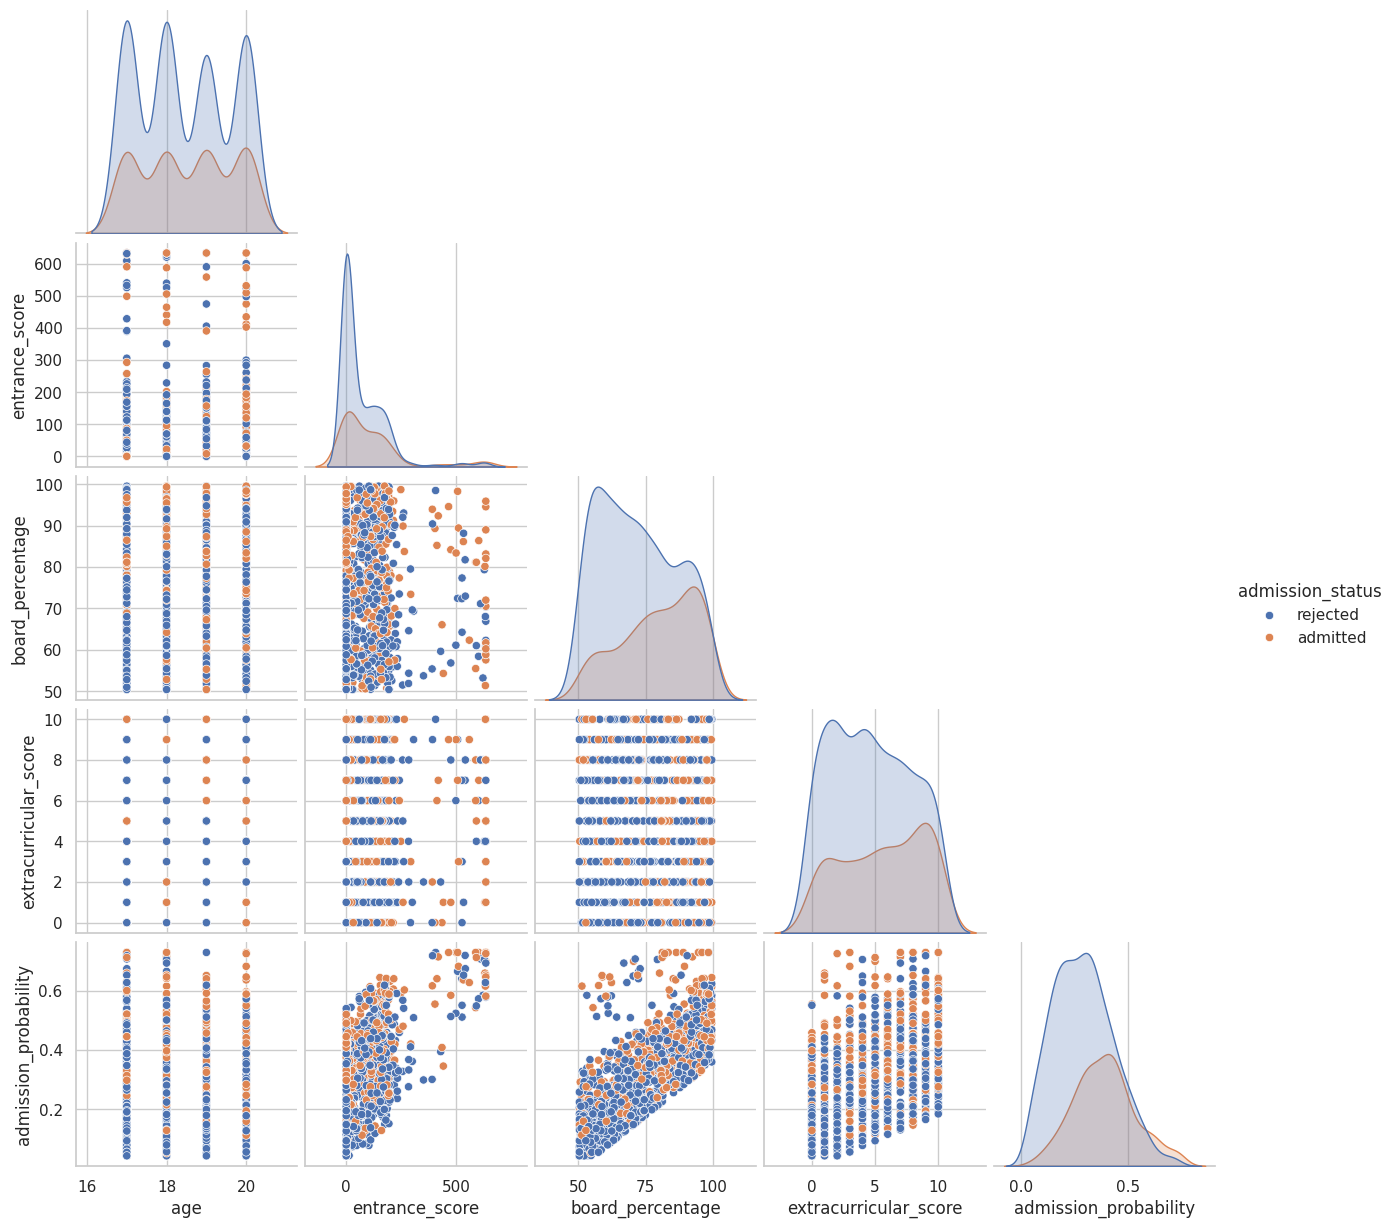

In [37]:
# Plot 24: Pairplot on a sample for speed
sample = clean_df.sample(min(1200, len(clean_df)), random_state=42)
sns.pairplot(sample, vars=["age","entrance_score","board_percentage","extracurricular_score","admission_probability"], hue="admission_status", corner=True)
plt.show()

In [38]:
# 6. Admission-rate metrics for categorical features
for col in ["gender","category","state","preferred_stream","entrance_exam","scholarship_eligibility"]:
    print("\n", "="*55, "\n", col)
    rates = clean_df.groupby(col)["admission_status"].apply(
        lambda x: (x == "admitted").mean()*100
    ).sort_values(ascending=False)
    display(rates.round(2).to_frame("Admission Rate (%)"))


 gender


,Admission Rate (%)
gender,
other,33.12
female,32.69
male,32.01



 category


,Admission Rate (%)
category,
obc,33.29
ews,33.00
st,32.71
general,32.40
sc,31.63



 state


...

,Admission Rate (%)
preferred_stream,
medical,49.75
engineering,38.85
architecture,32.73
pharmacy,32.10
agriculture,30.82
nursing,30.41
commerce,30.36
law,29.73
science,29.51



 entrance_exam


,Admission Rate (%)
entrance_exam,
neet,49.75
jee,39.92
cet,34.37
none,27.08



 scholarship_eligibility


,Admission Rate (%)
scholarship_eligibility,
yes,100.00
no,15.53


## Baseline vs Improved Model

In [39]:
# 7. Prepare classification target
model_df = clean_df.copy()
model_df["target"] = model_df["admission_status"].map({"rejected":0, "admitted":1})

# Exclude the target and probability-like score from the strict baseline
X = model_df.drop(columns=["admission_status", "target", "admission_probability"])
y = model_df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=.20, random_state=42, stratify=y
)

cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()

prep = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])

In [40]:
# 8. Baseline Logistic Regression
baseline = Pipeline([
    ("preprocessor", prep),
    ("model", LogisticRegression(max_iter=2000))
])
baseline.fit(X_train, y_train)

pred_b = baseline.predict(X_test)
prob_b = baseline.predict_proba(X_test)[:,1]

baseline_metrics = {
    "Accuracy": accuracy_score(y_test,pred_b),
    "Precision": precision_score(y_test,pred_b),
    "Recall": recall_score(y_test,pred_b),
    "F1 Score": f1_score(y_test,pred_b),
    "ROC-AUC": roc_auc_score(y_test,prob_b)
}
print("BASELINE LOGISTIC REGRESSION")
for k,v in baseline_metrics.items(): print(f"{k}: {v*100:.2f}%")

BASELINE LOGISTIC REGRESSION
Accuracy: 87.52%
Precision: 98.18%
Recall: 62.88%
F1 Score: 76.66%
ROC-AUC: 86.15%


In [41]:
# 9. Feature engineering
def engineer(data):
    d = data.copy()
    d["academic_average"] = ((d["entrance_score"]/10) + d["board_percentage"]) / 2
    d["score_board_gap"] = d["entrance_score"]/10 - d["board_percentage"]
    d["entrance_board_product"] = (d["entrance_score"]/1000) * d["board_percentage"]
    d["extracurricular_ratio"] = d["extracurricular_score"] / (d["board_percentage"] + 1e-6)
    d["age_squared"] = d["age"]**2
    return d

X_eng = engineer(X)
Xtr, Xte, ytr, yte = train_test_split(X_eng, y, test_size=.20, random_state=42, stratify=y)

cat_e = X_eng.select_dtypes(include="object").columns.tolist()
num_e = X_eng.select_dtypes(exclude="object").columns.tolist()

prep_e = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_e),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
    ]), cat_e)
])

In [42]:
# 10. Improved HistGradientBoosting
improved = Pipeline([
    ("preprocessor", prep_e),
    ("model", HistGradientBoostingClassifier(
        max_iter=300, learning_rate=.05, max_leaf_nodes=31,
        min_samples_leaf=15, l2_regularization=1.0, random_state=42
    ))
])
improved.fit(Xtr, ytr)

pred_i = improved.predict(Xte)
prob_i = improved.predict_proba(Xte)[:,1]

improved_metrics = {
    "Accuracy": accuracy_score(yte,pred_i),
    "Precision": precision_score(yte,pred_i),
    "Recall": recall_score(yte,pred_i),
    "F1 Score": f1_score(yte,pred_i),
    "ROC-AUC": roc_auc_score(yte,prob_i)
}
print("IMPROVED MODEL")
for k,v in improved_metrics.items(): print(f"{k}: {v*100:.2f}%")

IMPROVED MODEL
Accuracy: 87.36%
Precision: 94.87%
Recall: 64.72%
F1 Score: 76.95%
ROC-AUC: 92.51%


In [43]:
# 11. Metrics comparison
metrics = pd.DataFrame({
    "Metric": list(baseline_metrics.keys()),
    "Baseline": [v*100 for v in baseline_metrics.values()],
    "Improved": [v*100 for v in improved_metrics.values()]
})
metrics["Difference"] = metrics["Improved"] - metrics["Baseline"]
display(metrics.round(2))

relative_accuracy_improvement = (
    (improved_metrics["Accuracy"] - baseline_metrics["Accuracy"])
    / baseline_metrics["Accuracy"] * 100
)
print(f"Relative accuracy improvement: {relative_accuracy_improvement:.2f}%")

,Metric,Baseline,Improved,Difference
0,Accuracy,87.52,87.36,-0.16
1,Precision,98.18,94.87,-3.31
2,Recall,62.88,64.72,1.84
3,F1 Score,76.66,76.95,0.29
4,ROC-AUC,86.15,92.51,6.36


Relative accuracy improvement: -0.18%


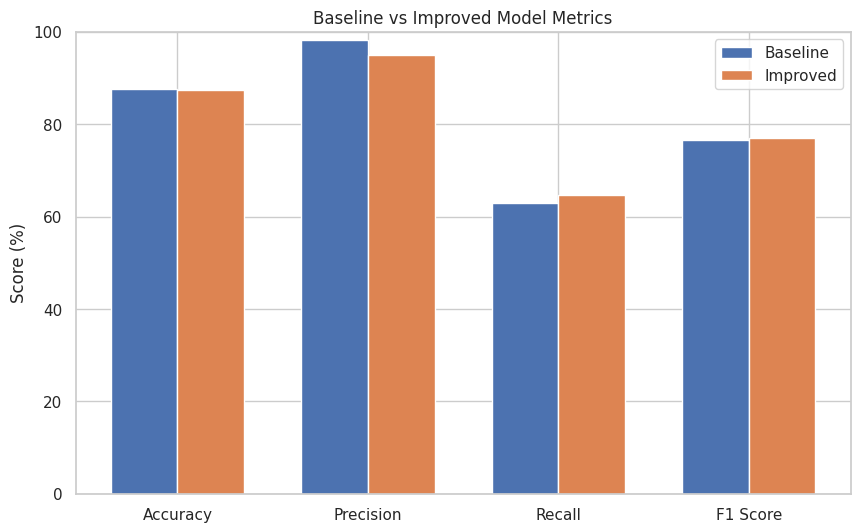

In [44]:
# Plot 25: Metrics comparison
m = metrics[metrics["Metric"] != "ROC-AUC"]
x = np.arange(len(m))
w = .35
plt.figure(figsize=(10,6))
plt.bar(x-w/2, m["Baseline"], w, label="Baseline")
plt.bar(x+w/2, m["Improved"], w, label="Improved")
plt.xticks(x, m["Metric"])
plt.ylabel("Score (%)")
plt.title("Baseline vs Improved Model Metrics")
plt.ylim(0,100)
plt.legend()
plt.show()

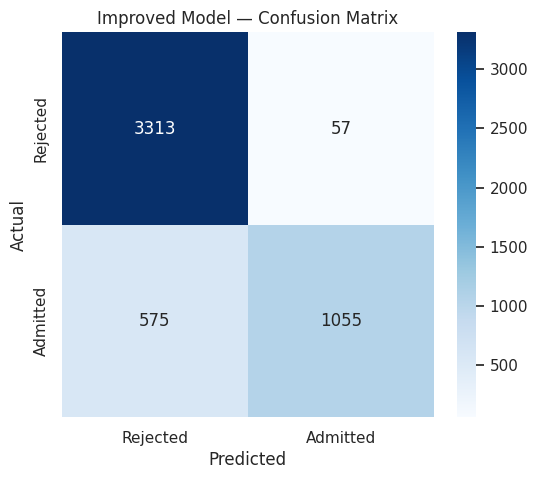

In [45]:
# Plot 26: Confusion matrix
cm = confusion_matrix(yte, pred_i)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Rejected","Admitted"],
            yticklabels=["Rejected","Admitted"])
plt.title("Improved Model — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

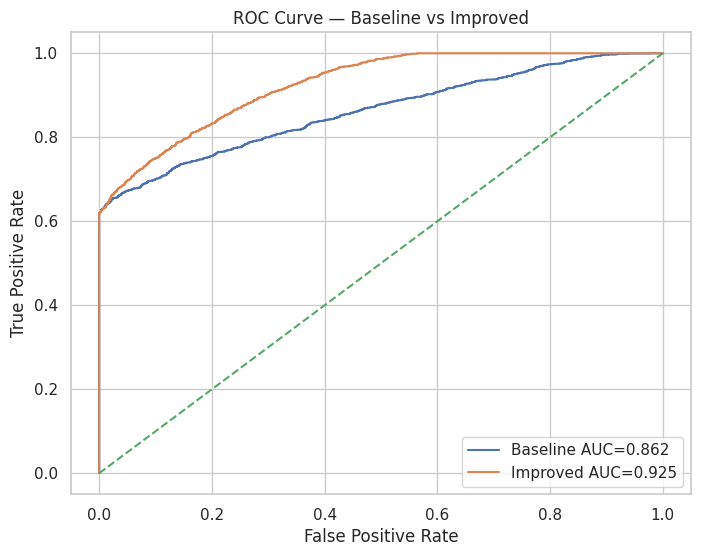

In [46]:
# Plot 27: ROC curve
fpr_b, tpr_b, _ = roc_curve(y_test, prob_b)
fpr_i, tpr_i, _ = roc_curve(yte, prob_i)

plt.figure(figsize=(8,6))
plt.plot(fpr_b, tpr_b, label=f"Baseline AUC={baseline_metrics['ROC-AUC']:.3f}")
plt.plot(fpr_i, tpr_i, label=f"Improved AUC={improved_metrics['ROC-AUC']:.3f}")
plt.plot([0,1],[0,1],"--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Baseline vs Improved")
plt.legend()
plt.show()

In [47]:
# 12. Classification reports
print("BASELINE")
print(classification_report(y_test, pred_b, target_names=["Rejected","Admitted"]))

print("\nIMPROVED")
print(classification_report(yte, pred_i, target_names=["Rejected","Admitted"]))

BASELINE
              precision    recall  f1-score   support

    Rejected       0.85      0.99      0.91      3370
    Admitted       0.98      0.63      0.77      1630

    accuracy                           0.88      5000
   macro avg       0.91      0.81      0.84      5000
weighted avg       0.89      0.88      0.87      5000


IMPROVED
              precision    recall  f1-score   support

    Rejected       0.85      0.98      0.91      3370
    Admitted       0.95      0.65      0.77      1630

    accuracy                           0.87      5000
   macro avg       0.90      0.82      0.84      5000
weighted avg       0.88      0.87      0.87      5000

